In [47]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
path = '../data/raw/credit_risk_dataset.csv'
df = pd.read_csv(path)

In [21]:
df.head(7)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
5,21,9900,OWN,2.0,VENTURE,A,2500,7.14,1,0.25,N,2
6,26,77100,RENT,8.0,EDUCATION,B,35000,12.42,1,0.45,N,3


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [23]:
(df.dtypes)

person_age                      int64
person_income                   int64
person_home_ownership          object
person_emp_length             float64
loan_intent                    object
loan_grade                     object
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file      object
cb_person_cred_hist_length      int64
dtype: object

In [24]:
df.isna().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [25]:
df.duplicated().sum()

np.int64(165)

In [26]:
df['loan_status'].value_counts(normalize=True)

loan_status
0    0.781836
1    0.218164
Name: proportion, dtype: float64

In [27]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


## 1. Аномальные значения

Проверяем, сколько строк с нереалистичными значениями в `person_age`, `person_emp_length` и `person_income`. Смотрим, сколько их, как они выглядят и совпадают ли между собой. Ничего не удаляем: решение примем после просмотра и запишем отдельной ячейкой.

In [28]:
# Возраст
print("Возраст > 80: ", (df["person_age"] > 80).sum())
print("Возраст > 100:", (df["person_age"] > 100).sum())
print("Топ-10 возрастов:", df["person_age"].nlargest(10).tolist())

Возраст > 80:  7
Возраст > 100: 5
Топ-10 возрастов: [144, 144, 144, 123, 123, 94, 84, 80, 78, 76]


In [29]:
# Стаж
print("\nСтаж > 40:", (df["person_emp_length"] > 40).sum())
print("Топ-10 стажей:", df["person_emp_length"].nlargest(10).tolist())


Стаж > 40: 3
Топ-10 стажей: [123.0, 123.0, 41.0, 38.0, 34.0, 31.0, 31.0, 31.0, 31.0, 30.0]


In [30]:
# Стаж больше, чем возраст минус 14 (начал работать до 14 лет)
impossible_exp = df["person_emp_length"] > (df["person_age"] - 14)
print("\nСтаж > возраст - 14:", impossible_exp.sum())


Стаж > возраст - 14: 2


In [31]:
# Доход
print("\nТоп-10 доходов:", df["person_income"].nlargest(10).tolist())
print("Доход > 1 000 000:", (df["person_income"] > 1_000_000).sum())


Топ-10 доходов: [6000000, 2039784, 1900000, 1782000, 1440000, 1362000, 1200000, 1200000, 1200000, 948000]
Доход > 1 000 000: 9


In [34]:
# Сами строки с аномалиями
anomalies = df[
    (df["person_age"] > 80)
    | (df["person_emp_length"] > 40)
    | impossible_exp
    | (df["person_income"] > 1_000_000)
]
print("\nВсего строк с аномалиями:", len(anomalies))
anomalies.sort_values("person_age", ascending=False)


Всего строк с аномалиями: 18


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,NaN,0,0.26,N,4
32416,94,24000,RENT,1.0,MEDICAL,C,6500,NaN,0,0.27,N,27
32506,84,94800,MORTGAGE,2.0,PERSONAL,A,10000,7.51,0,0.11,N,24
32355,78,48000,RENT,41.0,MEDICAL,A,3000,7.51,0,0.06,N,25
32497,63,1782000,RENT,13.0,EDUCATION,C,12025,14.27,0,0.01,N,30
32546,60,1900000,MORTGAGE,5.0,PERSONAL,A,1500,NaN,0,0.00,N,21


### Решение по аномалиям

Удаляем 18 строк (0,06% данных), попавших под любое из условий:
- `person_age` > 80: 5 строк с невозможным возрастом (123-144) и 2 с возрастом 84 и 94.
- `person_emp_length` > 40: стаж 123 года (заёмщикам 21 и 22 года) и стаж 41 при возрасте 78.
- `person_emp_length` > `person_age` - 14: стаж, начавшийся до 14 лет (те же строки со стажем 123).
- `person_income` > 1 000 000: 9 строк, экстремальные значения на правом хвосте.

Причины: часть строк содержит явные ошибки ввода, остальные это единичные экстремумы, которые ничего не добавляют для обучения и могут искажать статистику. Потеря данных пренебрежимо мала. В `src/data.py` правило реализуем теми же порогами.

In [36]:
before = len(df)
df = df.drop(index=anomalies.index, errors="ignore")
print(f"Удалено: {before - len(df)}, осталось: {len(df)}")

Удалено: 18, осталось: 32563


## 2. Природа пропусков

Пропуски есть в `person_emp_length` и `loan_int_rate`. Проверяем, случайные они или нет: отличается ли доля дефолтов в строках с пропуском, сидят ли пропуски в определённых категориях и пересекаются ли они между собой. От этого зависит, как их заполнять.

In [37]:
cols = ["person_emp_length", "loan_int_rate"]

In [38]:
# Сколько пропусков после удаления аномалий
print(df[cols].isna().sum())
print("Пропуски в обоих столбцах сразу:", df[cols].isna().all(axis=1).sum())

person_emp_length     895
loan_int_rate        3112
dtype: int64
Пропуски в обоих столбцах сразу: 68


In [ ]:
# Доля дефолтов: строки с пропуском и без него
for col in cols:
    print(f"\n{col}: доля дефолтов")
    print(df.groupby(df[col].isna())["loan_status"].mean().rename({False: "без пропуска", True: "с пропуском"}))


person_emp_length: доля дефолтов
person_emp_length
без пропуска    0.215517
с пропуском     0.315084
Name: loan_status, dtype: float64

loan_int_rate: доля дефолтов
loan_int_rate
без пропуска    0.219449
с пропуском     0.206941
Name: loan_status, dtype: float64


In [40]:
# Где сидят пропуски: доля пропусков по категориям
for col in cols:
    for cat in ["loan_grade", "loan_intent", "person_home_ownership"]:
        print(f"\nДоля пропусков {col} по {cat}:")
        print(df[col].isna().groupby(df[cat]).mean().round(3))


Доля пропусков person_emp_length по loan_grade:
loan_grade
A    0.038
B    0.025
C    0.021
D    0.019
E    0.012
F    0.021
G    0.000
Name: person_emp_length, dtype: float64

Доля пропусков person_emp_length по loan_intent:
loan_intent
DEBTCONSOLIDATION    0.028
EDUCATION            0.025
HOMEIMPROVEMENT      0.026
MEDICAL              0.029
PERSONAL             0.028
VENTURE              0.029
Name: person_emp_length, dtype: float64

Доля пропусков person_emp_length по person_home_ownership:
person_home_ownership
MORTGAGE    0.026
OTHER       0.000
OWN         0.067
RENT        0.023
Name: person_emp_length, dtype: float64

Доля пропусков loan_int_rate по loan_grade:
loan_grade
A    0.093
B    0.101
C    0.097
D    0.086
E    0.086
F    0.112
G    0.078
Name: loan_int_rate, dtype: float64

Доля пропусков loan_int_rate по loan_intent:
loan_intent
DEBTCONSOLIDATION    0.098
EDUCATION            0.093
HOMEIMPROVEMENT      0.087
MEDICAL              0.102
PERSONAL             0.092
VEN

In [43]:
# Чем отличаются строки с пропуском в loan_int_rate
print("\nСредние значения: без пропуска / с пропуском в loan_int_rate")
num_cols = ["person_age", "person_income", "loan_amnt", "loan_percent_income", "cb_person_cred_hist_length"]
print(df.groupby(df["loan_int_rate"].isna())[num_cols].mean().round(2))


Средние значения: без пропуска / с пропуском в loan_int_rate
               person_age  person_income  loan_amnt  loan_percent_income  \
loan_int_rate                                                              
False               27.69       65510.36    9583.88                 0.17   
True                27.86       65645.72    9633.29                 0.17   

               cb_person_cred_hist_length  
loan_int_rate                              
False                                5.78  
True                                 5.94  


### Решение по пропускам

- Строки с пропусками не удаляем: их около 12% данных, и среди них повышенная доля дефолтов.
- `person_emp_length` (895 пропусков, 2,7%): пропуски не случайны. Доля дефолтов с пропуском 31,5% против 21,6% без него, и у `person_home_ownership = OWN` пропусков 6,7% против 2-3% у остальных. Заполняем медианой и добавляем признак «стаж пропущен».
- `loan_int_rate` (3 112 пропусков, 9,6%): пропуски похожи на случайные. Доля дефолтов и средние других признаков с пропуском и без практически не отличаются, по категориям пропуски распределены равномерно. Заполняем медианой внутри `loan_grade`, так как грейд определяет ставку.
- Пропуски в двух столбцах сразу: 68 строк, связи между ними нет.
- Заполнение выполняем в пайплайне после разбиения на train и test, чтобы избежать утечки.

## 3. Категориальные признаки

Смотрим четыре категориальных признака: `person_home_ownership`, `loan_intent`, `loan_grade` и `cb_person_default_on_file`. Для каждого считаем размер групп и долю дефолтов. Ищем редкие категории (по ним доля дефолтов ненадёжна) и признаки, которые сильно различают заёмщиков.

In [45]:
cat_cols = ["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"]

In [46]:
for col in cat_cols:
    stats = (
        df.groupby(col)["loan_status"]
        .agg(строк="size", доля_дефолтов="mean")
        .assign(доля_строк=lambda x: x["строк"] / len(df))
        .round(3)
        .sort_values("доля_дефолтов", ascending=False)
    )
    print(f"\n{col}")
    print(stats)


person_home_ownership
                       строк  доля_дефолтов  доля_строк
person_home_ownership                                  
RENT                   16438          0.316       0.505
OTHER                    107          0.308       0.003
MORTGAGE               13435          0.126       0.413
OWN                     2583          0.075       0.079

loan_intent
                   строк  доля_дефолтов  доля_строк
loan_intent                                        
DEBTCONSOLIDATION   5211          0.286       0.160
MEDICAL             6067          0.267       0.186
HOMEIMPROVEMENT     3605          0.261       0.111
PERSONAL            5517          0.199       0.169
EDUCATION           6450          0.172       0.198
VENTURE             5713          0.148       0.175

loan_grade
            строк  доля_дефолтов  доля_строк
loan_grade                                  
G              64          0.984       0.002
F             241          0.705       0.007
E             964   

### Решение по категориальным признакам

- Все четыре признака различают заёмщиков: доля дефолтов варьируется от 7,5% до 98,4% в зависимости от категории.
- `loan_grade`: доля дефолтов монотонно растёт от A (10,0%) к G (98,4%), с резким скачком между C и D (с 20,8% до 59,0%). Признак порядковый, кодируем числами (A=0 … G=6).
- `person_home_ownership`, `loan_intent`: порядка нет, кодируем one-hot. Категорию `OTHER` (107 строк, 0,3%) не объединяем с другими, так как её смысл неизвестен.
- `cb_person_default_on_file`: бинарный, кодируем 0/1.
- Вопрос про использование `loan_grade` (и `loan_int_rate`) как признаков решаем в baseline: они назначаются банком до выдачи кредита.
- Кодирование реализуем в пайплайне, в EDA данные не меняем.

## 4. Числовые признаки и целевая переменная

Сравниваем распределения числовых признаков для заёмщиков, которые погасили кредит (0), и тех, кто ушёл в дефолт (1). Смотрим медианы по классам и боксплоты. Доход показываем в логарифмической шкале из-за сильной скошенности. Ищем признаки, у которых классы заметно различаются.

In [49]:
num_cols = [
    "person_age", "person_income", "person_emp_length", "loan_amnt",
    "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length",
]

In [50]:
# Медианы по классам
print(df.groupby("loan_status")[num_cols].median().T.rename(columns={0: "погашен", 1: "дефолт"}))

loan_status                  погашен    дефолт
person_age                     26.00     26.00
person_income               60000.00  41496.00
person_emp_length               4.00      3.00
loan_amnt                    8000.00   9600.00
loan_int_rate                  10.59     13.49
loan_percent_income             0.13      0.24
cb_person_cred_hist_length      4.00      4.00


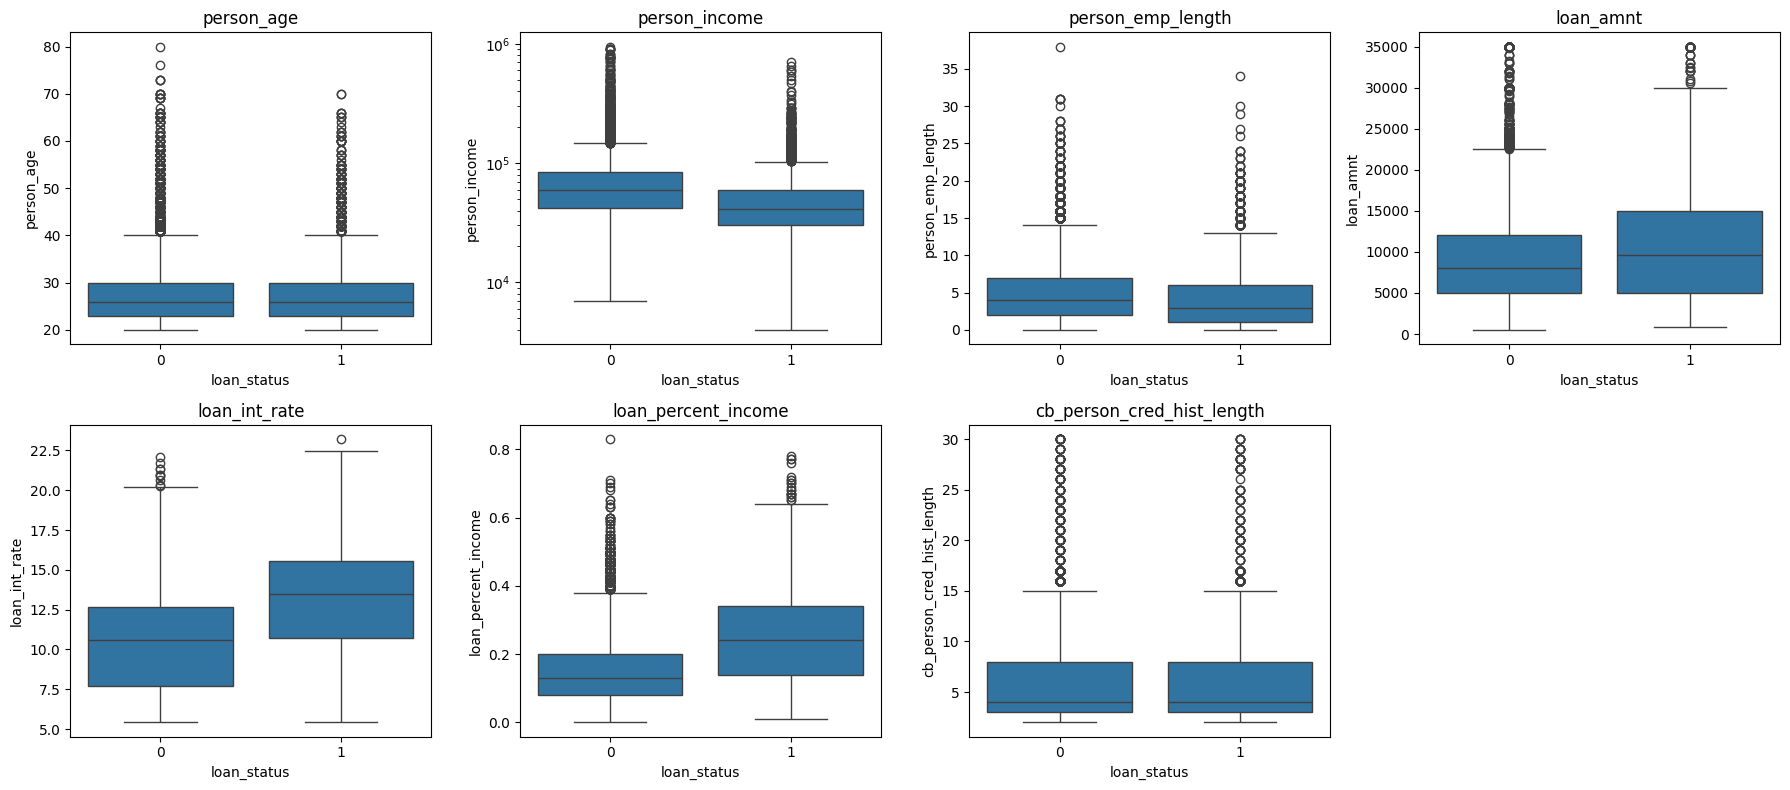

In [51]:
# Боксплоты по классам
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(data=df, x="loan_status", y=col, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("loan_status")
    if col == "person_income":
        ax.set_yscale("log")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

### Выводы по числовым признакам

- Сильно различают классы: `loan_percent_income` (медиана 0,13 против 0,24), `loan_int_rate` (10,59 против 13,49), `person_income` (60 000 против 41 496).
- Слабее: `loan_amnt` (8 000 против 9 600) и `person_emp_length` (4 против 3 года).
- Почти не различают по отдельности: `person_age` и `cb_person_cred_hist_length` (медианы совпадают). Не исключаем, связь между ними проверим отдельно.
- Точки за «усами» есть почти у всех признаков, это следствие скошенных распределений, а не ошибок. Нужность смягчения выбросов решаем в baseline в зависимости от модели.
- Медиана `loan_int_rate` посчитана без пропусков.

## 5. Связи между признаками

Проверяем, как признаки связаны друг с другом и согласуются ли между собой:
- `loan_grade` и `loan_int_rate`: определяет ли грейд ставку.
- `loan_percent_income` и отношение суммы кредита к доходу: совпадают ли они.
- `person_age` и `cb_person_cred_hist_length`: не длиннее ли кредитная история, чем взрослая жизнь заёмщика.
- Матрица корреляций числовых признаков: нет ли пар, которые почти дублируют друг друга.

Данные пока не меняем.

In [52]:
# 1. Грейд и ставка
print(df.groupby("loan_grade")["loan_int_rate"].describe()[["count", "min", "50%", "max"]].round(2))

             count    min    50%    max
loan_grade                             
A           9767.0   5.42   7.49   9.63
B           9393.0   6.00  10.99  12.69
C           5824.0   6.00  13.48  16.11
D           3313.0   6.00  15.31  18.49
E            881.0   6.00  16.82  20.69
F            214.0  15.01  18.54  22.06
G             59.0  17.34  20.16  23.22


In [ ]:
# 2. loan_percent_income против суммы / дохода
calc = df["loan_amnt"] / df["person_income"]
diff = (calc - df["loan_percent_income"]).abs()
print("\nРасхождение loan_percent_income > 0.01:", (diff > 0.01).sum())


Расхождение loan_percent_income > 0.01: 388


In [54]:
# 3. Кредитная история длиннее, чем возраст минус 18
too_long = df["cb_person_cred_hist_length"] > (df["person_age"] - 18)
print("Кредитная история > возраст - 18:", too_long.sum())
print(df.loc[too_long, ["person_age", "cb_person_cred_hist_length"]].head(10))

Кредитная история > возраст - 18: 780
     person_age  cb_person_cred_hist_length
35           21                           4
60           21                           4
77           21                           4
148          21                           4
167          21                           4
171          21                           4
189          21                           4
229          21                           4
325          21                           4
350          21                           4


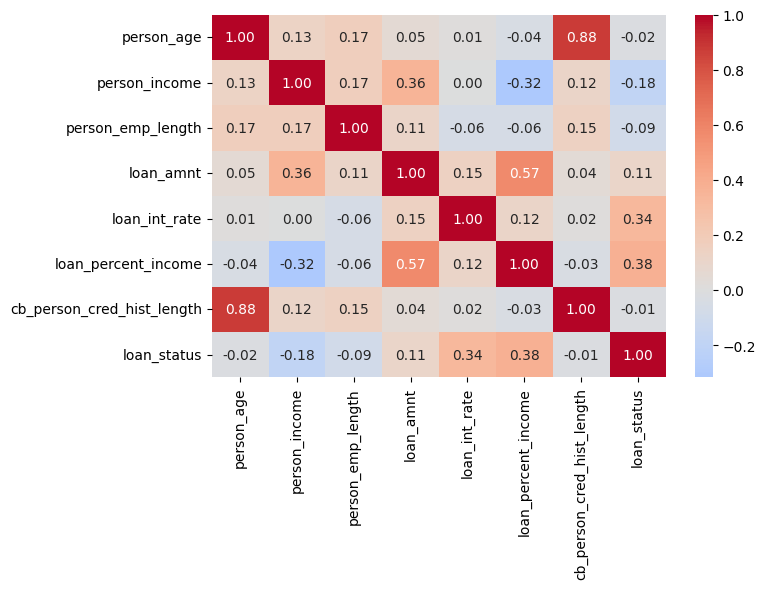

In [55]:
# 4. Корреляции числовых признаков и цели
num_cols = [
    "person_age", "person_income", "person_emp_length", "loan_amnt",
    "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length",
]
corr = df[num_cols + ["loan_status"]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.tight_layout()
plt.show()

In [57]:
# 1. Строки, где loan_percent_income не сходится с расчётом
calc = df["loan_amnt"] / df["person_income"]
diff = calc - df["loan_percent_income"]
mismatch = df[diff.abs() > 0.01].assign(расчёт=calc.round(2))
print("Расхождений:", len(mismatch))
print(mismatch[["person_income", "loan_amnt", "loan_percent_income", "расчёт"]].head(10))
print("Расчёт больше указанного:", (diff[mismatch.index] > 0).sum())

Расхождений: 388
     person_income  loan_amnt  loan_percent_income  расчёт
4            54400      35000                 0.55    0.64
17           92111      35000                 0.32    0.38
40           62050      30000                 0.41    0.48
48           66300      30000                 0.38    0.45
63          221850      25000                 0.10    0.11
202          56100      25000                 0.38    0.45
224          62050      25000                 0.34    0.40
255         142800      10000                 0.06    0.07
260          66215      25000                 0.32    0.38
270          66300      25000                 0.32    0.38
Расчёт больше указанного: 388


In [ ]:
# 2. Разрыв между возрастом и длиной кредитной истории
gap = df["person_age"] - df["cb_person_cred_hist_length"]
print("\n", gap.describe())
for t in (18, 16, 14):
    print(f"возраст - история < {t}:", (gap < t).sum())


 count    32563.000000
mean        21.909099
std          3.257225
min         16.000000
25%         20.000000
50%         21.000000
75%         23.000000
max         55.000000
dtype: float64
возраст - история < 18: 780
возраст - история < 16: 0
возраст - история < 14: 0


### Выводы по связям между признаками

- `loan_grade` и `loan_int_rate`: ставка растёт ступенями от A (медиана 7,49) к G (20,16), но диапазоны перекрываются, то есть внутри грейда есть разброс. Использование обоих признаков решаем в baseline.
- `person_age` и `cb_person_cred_hist_length`: корреляция 0,88, при этом оба слабо связаны с целью (-0,02 и -0,01). Разрыв «возраст минус кредитная история» не меньше 16 лет ни в одной строке, поэтому значения считаем правдоподобными и ничего не удаляем. Нужность обоих признаков для линейных моделей решаем в baseline.
- `loan_percent_income`: в 388 строках (1,2%) указанное значение меньше `loan_amnt / person_income`, всегда в одну сторону (примерно в 0,85 раза), `loan_amnt` в этих строках круглые суммы. Какое из полей верно, неизвестно. Строки не удаляем. Открытый вопрос: как считать этот признак в API, чтобы определение совпадало с обучением.

## 6. Дубликаты

Проверяем полностью совпадающие строки. Смотрим, сколько их, из скольких копий состоят группы, чем они отличаются по доле дефолтов от остальных данных и есть ли строки с одинаковыми признаками, но разной целью. Данные пока не меняем.

In [59]:
cols = list(df.columns)
dup_mask = df.duplicated(keep=False)

print("Лишних копий (если оставить по одной):", df.duplicated().sum())
print("Строк, входящих в группы дубликатов:  ", dup_mask.sum())

Лишних копий (если оставить по одной): 165
Строк, входящих в группы дубликатов:   330


In [60]:
# Из скольких копий состоят группы
group_sizes = df[dup_mask].groupby(cols, dropna=False).size()
print("\nРазмер группы -> сколько таких групп")
print(group_sizes.value_counts().sort_index())


Размер группы -> сколько таких групп
2    165
Name: count, dtype: int64


In [61]:
# Доля дефолтов: строки-дубликаты и все данные
print("\nДоля дефолтов среди дубликатов:", round(df.loc[dup_mask, "loan_status"].mean(), 3))
print("Доля дефолтов во всех данных:  ", round(df["loan_status"].mean(), 3))


Доля дефолтов среди дубликатов: 0.115
Доля дефолтов во всех данных:   0.218


In [62]:
# Одинаковые признаки, но разная цель
features = [c for c in cols if c != "loan_status"]
n_targets = df.groupby(features, dropna=False)["loan_status"].nunique()
print("\nГрупп с одинаковыми признаками, но разной целью:", (n_targets > 1).sum())


Групп с одинаковыми признаками, но разной целью: 0


In [65]:
# Несколько примеров
df[dup_mask].sort_values(cols).head(10)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
15944,21,8088,RENT,NaN,MEDICAL,C,1200,15.23,0,0.15,Y,2
16835,21,8088,RENT,NaN,MEDICAL,C,1200,15.23,0,0.15,Y,2
2431,21,15600,RENT,0.0,MEDICAL,A,2800,7.40,1,0.18,N,4
17758,21,15600,RENT,0.0,MEDICAL,A,2800,7.40,1,0.18,N,4
2498,21,18000,RENT,0.0,DEBTCONSOLIDATION,A,3000,7.90,1,0.17,N,2
17601,21,18000,RENT,0.0,DEBTCONSOLIDATION,A,3000,7.90,1,0.17,N,2
1778,21,20000,RENT,0.0,MEDICAL,A,2000,NaN,0,0.10,N,3
17642,21,20000,RENT,0.0,MEDICAL,A,2000,NaN,0,0.10,N,3
740,21,21600,OWN,NaN,VENTURE,A,7125,6.99,0,0.33,N,3
17283,21,21600,OWN,NaN,VENTURE,A,7125,6.99,0,0.33,N,3


### Решение по дубликатам

- Найдено 165 пар полностью совпадающих строк (по 2 копии в каждой, групп побольше нет).
- Конфликтов нет: нет строк с одинаковыми признаками и разной целью. При случайных совпадениях разных заёмщиков такие конфликты были бы (ожидалось бы порядка 30 пар), значит, это настоящие копии записей.
- Доля дефолтов среди дубликатов 11,5% против 21,8% во всех данных, но удаление 165 строк почти не меняет баланс классов (около 21,9%).
- Удаляем лишние копии, оставляя первую. Это защищает от утечки: иначе копия одной записи может попасть и в train, и в test, и метрики будут завышены.
- Удаление реализуем в `src/data.py` до разбиения на train и test.

In [66]:
before = len(df)
df = df.drop_duplicates(keep="first")
print(f"Удалено: {before - len(df)}, осталось: {len(df)}")
print("Доля дефолтов:", round(df["loan_status"].mean(), 4))

Удалено: 165, осталось: 32398
Доля дефолтов: 0.2188


## Итоги EDA

Исходно 32 581 строка, после очистки 32 398 (удалено 183, 0,56%). Доля дефолтов 21,8% до очистки и около 21,9% после.

### Что делает очистка (реализуем в `src/data.py`)
1. Удаляем 18 строк с аномалиями: `person_age` > 80, `person_emp_length` > 40 или > `person_age` - 14, `person_income` > 1 000 000.
2. Удаляем 165 лишних копий дубликатов, оставляя первую запись.
3. Пропуски в данных не удаляем, а заполняем позже в пайплайне.

### Что делает пайплайн (реализуем в `src/features.py`, после разбиения на train и test)
- `person_emp_length`: медиана и признак «стаж пропущен».
- `loan_int_rate`: медиана внутри `loan_grade`.
- `loan_grade`: порядковое кодирование (A=0 … G=6).
- `person_home_ownership`, `loan_intent`: one-hot, `OTHER` не объединяем.
- `cb_person_default_on_file`: 0/1.

### Что выяснили про данные
- Сильнее всего с целью связаны `loan_percent_income`, `loan_int_rate`, `person_income`, `loan_grade`, `person_home_ownership`. Возраст и длина кредитной истории по отдельности почти ничего не различают.
- `loan_percent_income` в 388 строках (1,2%) не совпадает с `loan_amnt / person_income`, оставляем как есть.

### Открытые вопросы для baseline
- Использовать ли `loan_grade` и `loan_int_rate`: они назначаются банком до выдачи, и по ним есть риск утечки. Сравниваем модели с ними и без них.
- `person_age` и `cb_person_cred_hist_length` связаны (корреляция 0,88): нужны ли оба для линейных моделей.
- Нужно ли смягчать выбросы (доход, сумма, возраст) зависит от выбранной модели.
- Как API считает `loan_percent_income`, чтобы определение совпадало с обучением. Также стоит ограничить входные значения в `app/schemas.py`: модель не видела доход больше 1 000 000 и возраст больше 80.